<a href="https://colab.research.google.com/github/DataScience-Fatec-Projects/ICD-004-Analise_de_Algoritmos/blob/main/Aulas/09/atividade06-grafos-bfs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Atividade 06 - Grafos com dicionário e Busca em Largura (BFS)**
### Fatec Deputado Ary Fossen - Jundiaí
**Disciplina:** ICD-004 - Análise de Algoritmos

**Integrantes:** Wellington Junior Torres de Melo

---

## Enunciado

> **1 - Modelagem de um grafo com dicionário em Python.** Desenvolva uma representação de grafo
> utilizando um dicionário em Python, onde cada chave é um vértice e o valor associado é uma lista
> (ou conjunto) de seus vértices adjacentes. Modele pelo menos cinco vértices com conexões variadas.
> Em seguida, imprima a estrutura criada e explique como ela representa as relações entre os elementos.
>
> **2 - Implementação da BFS para encontrar o caminho mais curto.** Implemente a BFS como uma função
> que recebe o grafo, o vértice de origem e o de destino, e retorna a lista dos vértices do caminho
> mais curto, ou indica quando não existe caminho. Teste em ao menos dois pares diferentes de vértices.
>
> **3 - Discussão de aplicações práticas.** Escolha um cenário real e explique como a representação
> de grafos e a BFS podem ser aplicadas para solucionar problemas em Ciência de Dados.

## Tema escolhido: a rede de Metrô/CPTM de São Paulo

| Grafo | Metrô |
|---|---|
| vértice | estação (só as de baldeação, para o grafo ter cruzamentos) |
| aresta | trecho direto entre duas dessas estações |
| caminho mais curto (BFS) | trajeto com **menos trechos** entre duas estações |

A BFS conta *trechos*, não minutos: todas as arestas valem o mesmo. Para considerar tempo de viagem
seria preciso pesar as arestas e usar Dijkstra, que vem depois da BFS no curso.

# 1. Modelagem do grafo com dicionário

Decisões de modelagem:

- **Dicionário de listas de adjacência:** a chave é a estação e o valor é a lista das estações
  vizinhas. Perguntar "quem são os vizinhos de X?" é um acesso `metro[X]`, em O(1) médio, pelo hash
  do `dict` (Atividade 05).
- **Lista, e não `set`, para os vizinhos:** a ordem de um `set` de strings muda entre execuções
  (hash aleatório das strings). Com lista, a BFS percorre os vizinhos sempre na mesma ordem e devolve
  sempre o mesmo caminho quando há empate.
- **Grafo não direcionado:** o trem anda nos dois sentidos, então cada trecho aparece **nas duas
  pontas**: `'Luz'` está na lista de `'Sé'` e `'Sé'` está na lista de `'Luz'`.
- **A linha (L1, L3...) fica no comentário**, porque ela é uma informação da aresta, e não da estação.
- **Um componente isolado de propósito:** Aeroporto-Guarulhos – Engenheiro Goulart (L13) sem a
  ligação com o resto, para testar na questão 2 o caso em que **não existe caminho**.

In [1]:
# grafo estacoes de metro
# vertice = estacao | aresta = trecho direto entre duas estacoes de baldeacao
# a linha fica no comentario, ao lado de cada vizinho (ela pertence a aresta, nao a estacao)
#
#                                                      Luz ----L11---- Brás
#                                                L4 /      \ L1     / L3
#                                                 /          \    /
# Jundiaí --L7-- Palmeiras-Barra Funda --L3-- República --L3-- Sé
#                                                 |            |
#                                                 L4           L1
#                                                 |            |
#                               Paulista-Consolação ---L2----- Paraíso
#
# Aeroporto-Guarulhos --L13-- Engenheiro Goulart   (isolado: sem a L12)
#
metro = {
    'Jundiaí': ['Palmeiras-Barra Funda'],                    # L7
    'Palmeiras-Barra Funda': ['Jundiaí','República'],
    'República': ['Palmeiras-Barra Funda','Luz','Sé','Paulista-Consolação'],
    'Luz': ['República','Brás','Sé'],
    'Brás': ['Luz','Sé'],
    'Paulista-Consolação': ['República','Paraíso'],
    'Paraíso': ['Paulista-Consolação','Sé'],
    'Sé': ['Luz','Brás','República','Paraíso'],
    'Aeroporto-Guarulhos': ['Engenheiro Goulart'],
    'Engenheiro Goulart': ['Aeroporto-Guarulhos']
}

### Imprimindo a estrutura

O código abaixo percorre o dicionário com `.items()` e mostra cada estação com os seus vizinhos. Depois
conta vértices e arestas: o grau de uma estação é o tamanho da sua lista e, como cada aresta aparece
nas duas pontas, a soma dos graus é o dobro do número de arestas (*lema do aperto de mãos*). Por fim,
uma checagem de simetria confirma que nenhuma ligação foi digitada só de um lado.

In [2]:
for estacao, vizinhos in metro.items():
    print(f"{estacao:<22} -> {', '.join(vizinhos)}")

# grau = tamanho da lista de vizinhos; cada aresta aparece nas duas pontas,
# entao soma dos graus = 2 x arestas (lema do aperto de maos)
soma_graus = sum(len(vizinhos) for vizinhos in metro.values())
total_arestas = soma_graus // 2

print(f"Total de vértices: {len(metro)}")
print(f"Soma dos graus:    {soma_graus}")
print(f"Total de arestas:  {total_arestas}")

# checagem de simetria: se A tem B como vizinho, B tem que ter A
RED_BOLD = "\033[1;31m"
RESET = "\033[0m"

ok = True
for estacao, vizinhos in metro.items():
    for vizinho in vizinhos:
        if vizinho not in metro:
            ok = False
            print(f"Vizinho {RED_BOLD}{vizinho}{RESET} (de {estacao}) sem chave própria.")
        elif estacao not in metro[vizinho]:
            ok = False
            print(f"Ligação só de um lado: {estacao} -> {RED_BOLD}{vizinho}{RESET}, "
                  f"mas {vizinho} não tem {estacao}.")

if ok:
    print("Simetria OK: todas as ligações aparecem nos dois sentidos.")

Jundiaí                -> Palmeiras-Barra Funda
Palmeiras-Barra Funda  -> Jundiaí, República
República              -> Palmeiras-Barra Funda, Luz, Sé, Paulista-Consolação
Luz                    -> República, Brás, Sé
Brás                   -> Luz, Sé
Paulista-Consolação    -> República, Paraíso
Paraíso                -> Paulista-Consolação, Sé
Sé                     -> Luz, Brás, República, Paraíso
Aeroporto-Guarulhos    -> Engenheiro Goulart
Engenheiro Goulart     -> Aeroporto-Guarulhos
Total de vértices: 10
Soma dos graus:    22
Total de arestas:  11
Simetria OK: todas as ligações aparecem nos dois sentidos.


### Como a estrutura representa as relações

- **Cada chave é um elemento** (estação) e **cada item da lista é uma relação** dela: `metro['Sé']`
  devolve `['Luz', 'Brás', 'República', 'Paraíso']`, ou seja, as quatro estações às quais se chega a
  partir da Sé sem passar por outra estação de baldeação.
- **O grau aparece direto:** `len(metro['Sé']) == 4`, a Sé e a República são os maiores
  *hubs* do recorte; Jundiaí tem grau 1 (ponta de linha).
- **O que não está no dicionário também é informação:** não há como sair do par
  Aeroporto-Guarulhos / Engenheiro Goulart. O grafo tem **dois componentes conectados**.
- **Resultado:** 10 vértices, 11 arestas, simetria OK.

O desenho abaixo é gerado **a partir do próprio dicionário** (cada par chave → vizinho vira um traço),
com a cor oficial de cada linha.

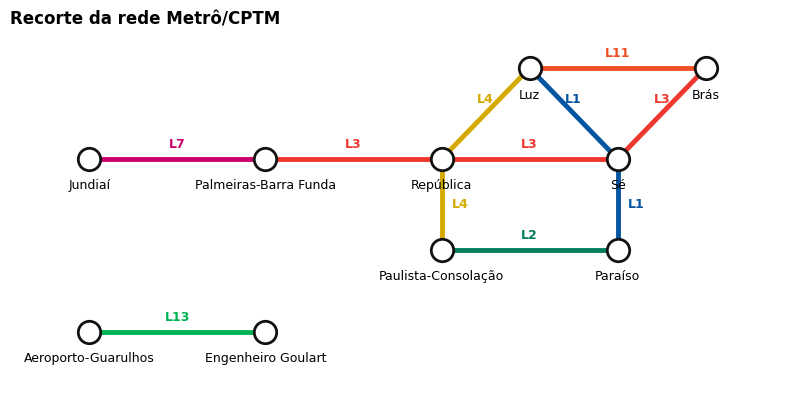

In [3]:
import matplotlib.pyplot as plt

# posicao de cada estacao no desenho (mesmo layout do comentario acima)
POS = {
    'Jundiaí': (0, 1), 'Palmeiras-Barra Funda': (2, 1), 'República': (4, 1), 'Sé': (6, 1),
    'Luz': (5, 2), 'Brás': (7, 2), 'Paulista-Consolação': (4, 0), 'Paraíso': (6, 0),
    'Aeroporto-Guarulhos': (0, -0.9), 'Engenheiro Goulart': (2, -0.9),
}
# a linha pertence a aresta: cor oficial de cada linha do Metro/CPTM
LINHA = {
    frozenset({'Jundiaí', 'Palmeiras-Barra Funda'}): ('L7', '#CA016B'),
    frozenset({'Palmeiras-Barra Funda', 'República'}): ('L3', '#EE372F'),
    frozenset({'República', 'Sé'}): ('L3', '#EE372F'),
    frozenset({'Brás', 'Sé'}): ('L3', '#EE372F'),
    frozenset({'Luz', 'Sé'}): ('L1', '#0455A1'),
    frozenset({'Sé', 'Paraíso'}): ('L1', '#0455A1'),
    frozenset({'República', 'Luz'}): ('L4', '#D4A900'),
    frozenset({'República', 'Paulista-Consolação'}): ('L4', '#D4A900'),
    frozenset({'Paulista-Consolação', 'Paraíso'}): ('L2', '#007E5E'),
    frozenset({'Luz', 'Brás'}): ('L11', '#F04E23'),
    frozenset({'Aeroporto-Guarulhos', 'Engenheiro Goulart'}): ('L13', '#00B352'),
}


def desenhar(grafo, caminho=None, titulo="Recorte da rede Metrô/CPTM"):
    """Desenha o grafo a partir do dicionario; se receber um caminho, destaca-o."""
    no_caminho = set()
    if caminho:
        no_caminho = {frozenset(p) for p in zip(caminho, caminho[1:])}
    fig, ax = plt.subplots(figsize=(10, 4.6))
    vistas = set()
    for estacao, vizinhos in grafo.items():          # percorre o dicionario: cada par vira um traco
        for vizinho in vizinhos:
            aresta = frozenset({estacao, vizinho})
            if aresta in vistas:                     # cada aresta aparece 2x no dict; desenha 1x
                continue
            vistas.add(aresta)
            nome, cor = LINHA[aresta]
            (x1, y1), (x2, y2) = POS[estacao], POS[vizinho]
            destaque = aresta in no_caminho
            ax.plot([x1, x2], [y1, y2], color=cor, lw=7 if destaque else 3.5,
                    alpha=1 if (destaque or not caminho) else 0.35, zorder=1, solid_capstyle='round')
            vertical = x1 == x2                      # rotulo ao lado do traco, longe dos nomes
            ax.text((x1 + x2) / 2 + (0.12 if vertical else 0), (y1 + y2) / 2 + (0 if vertical else 0.09),
                    nome, color=cor, fontsize=9, fontweight='bold',
                    ha='left' if vertical else 'center', va='center' if vertical else 'bottom')
    for estacao, (x, y) in POS.items():
        dentro = caminho and estacao in caminho
        ax.scatter(x, y, s=260, color='#111' if dentro else 'white', edgecolor='#111', lw=2, zorder=2)
        ax.text(x, y - 0.22, estacao, ha='center', va='top', fontsize=9,
                fontweight='bold' if dentro else 'normal')
    ax.set_title(titulo, loc='left', fontweight='bold')
    ax.set_xlim(-0.9, 7.9); ax.set_ylim(-1.5, 2.4); ax.axis('off')
    plt.show()


desenhar(metro)

# 2. BFS: caminho mais curto entre duas estações

A Busca em Largura explora o grafo em **ondas**: primeiro todas as estações a 1 trecho da origem,
depois todas a 2 trechos, e assim por diante. Ela usa uma **fila** (FIFO, `collections.deque`), que
garante essa ordem: quem entrou antes (mais perto da origem) sai antes. Por isso, **a primeira vez que
o destino é encontrado, o caminho tem o menor número de trechos possível**.

Cada item da fila guarda a estação e o caminho feito até ela, como no exemplo da aula. Três ajustes
em relação ao exemplo:

1. **Marca como visitado ao enfileirar.** No exemplo, a estação só vira "visitada" quando sai da fila,
   então a mesma estação pode entrar na fila várias vezes (por vizinhos diferentes) antes disso.
   Marcando na entrada, cada estação entra **uma única vez**.
2. **Casos de borda:** `origem == destino` devolve `[origem]`, e uma estação que não existe no grafo
   devolve `None` em vez de um `KeyError`.
3. **Testa o destino ao gerar o vizinho**, sem esperar ele sair da fila, o que economiza uma onda.

**Complexidade:** O(V + E). Cada estação entra na fila no máximo uma vez e cada lista de vizinhos
é percorrida uma vez. (Copiar o caminho a cada passo, `caminho + [vizinho]`, tem um custo extra
proporcional ao tamanho do caminho; em grafos muito grandes guarda-se só o "pai" de cada vértice e o
caminho é remontado no fim.)

In [4]:
# BFS (busca em largura) para achar o caminho com menos trechos entre duas estacoes
# base: exemplo da aula (exemplo.py), com tres ajustes:
#   1) marca como visitado AO ENFILEIRAR, e nao ao tirar da fila
#      (no exemplo a mesma estacao pode entrar varias vezes na fila antes de ser visitada)
#   2) trata origem == destino e estacao que nao existe no grafo
#   3) devolve None quando nao existe caminho
from collections import deque


def bfs_caminho_mais_curto(grafo, origem, destino):
    if origem not in grafo or destino not in grafo:
        return None                          # estacao fora do grafo
    if origem == destino:
        return [origem]                      # ja chegou, caminho de uma estacao so

    fila = deque([(origem, [origem])])       # cada item: (estacao atual, caminho ate ela)
    visitados = {origem}

    while fila:
        atual, caminho = fila.popleft()      # FIFO: sai primeiro quem esta mais perto da origem
        for vizinho in grafo[atual]:
            if vizinho in visitados:
                continue
            if vizinho == destino:
                return caminho + [vizinho]   # primeira vez que acha = menor numero de trechos
            visitados.add(vizinho)
            fila.append((vizinho, caminho + [vizinho]))

    return None                              # fila esvaziou sem achar: componentes separados


def mostrar(grafo, origem, destino):
    caminho = bfs_caminho_mais_curto(grafo, origem, destino)
    print(f"{origem} -> {destino}")
    if caminho is None:
        faltando = [e for e in (origem, destino) if e not in grafo]
        if faltando:
            print(f"   sem caminho: {', '.join(faltando)} não está no grafo\n")
        else:
            print("   sem caminho possível: as estações não estão ligadas\n")
    else:
        print(f"   {' → '.join(caminho)}")
        print(f"   {len(caminho)} estação(ões), {len(caminho) - 1} trecho(s)\n")

### Testes

O enunciado pede ao menos dois pares. Foram testados seis, cobrindo os casos que importam:

| Teste | O que verifica |
|---|---|
| Jundiaí → Paraíso | caminho longo, com duas baldeações (L7 → L3 → L1) |
| Brás → Paulista-Consolação | **empate**: há vários caminhos de 3 trechos; a ordem da lista decide qual sai |
| Luz → Sé | vizinhos diretos (1 trecho) |
| Jundiaí → Aeroporto-Guarulhos | **não existe caminho** (componentes diferentes) |
| Sé → Sé | origem igual ao destino |
| Jundiaí → Tatuapé | estação fora do grafo |

In [5]:
testes = [
    ('Jundiaí', 'Paraíso'),                     # L7 -> L3 -> L1: duas baldeacoes
    ('Brás', 'Paulista-Consolação'),            # empate: varios caminhos de 3 trechos, a ordem da lista decide
    ('Luz', 'Sé'),                              # vizinhos diretos
    ('Jundiaí', 'Aeroporto-Guarulhos'),         # L13 isolada: nao existe caminho
    ('Sé', 'Sé'),                               # origem == destino
    ('Jundiaí', 'Tatuapé'),                     # estacao fora do recorte
]
for origem, destino in testes:
    mostrar(metro, origem, destino)

Jundiaí -> Paraíso
   Jundiaí → Palmeiras-Barra Funda → República → Sé → Paraíso
   5 estação(ões), 4 trecho(s)

Brás -> Paulista-Consolação
   Brás → Luz → República → Paulista-Consolação
   4 estação(ões), 3 trecho(s)

Luz -> Sé
   Luz → Sé
   2 estação(ões), 1 trecho(s)

Jundiaí -> Aeroporto-Guarulhos
   sem caminho possível: as estações não estão ligadas

Sé -> Sé
   Sé
   1 estação(ões), 0 trecho(s)

Jundiaí -> Tatuapé
   sem caminho: Tatuapé não está no grafo



Conferindo no desenho: de Jundiaí ao Paraíso, a alternativa pela L4/L2
(República → Paulista-Consolação → Paraíso) também tem 4 trechos. A BFS devolve a que passa pela Sé
porque `'Sé'` vem antes de `'Paulista-Consolação'` na lista da República, e os dois caminhos estão na
mesma "onda". Ambos são mínimos, e com listas o resultado é o mesmo em toda execução.

O caminho encontrado, destacado no grafo:

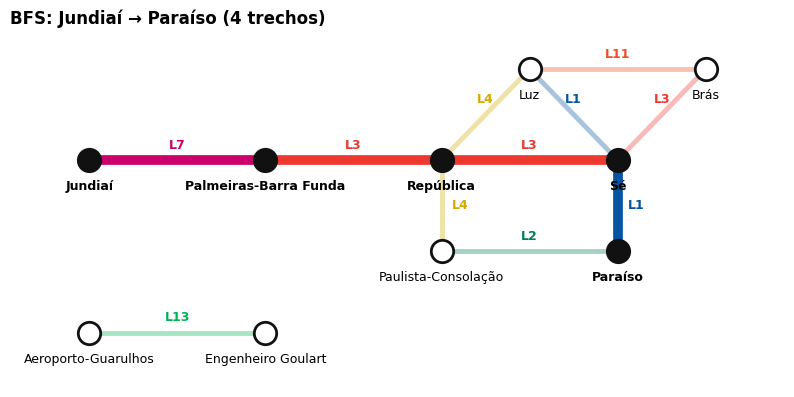

In [6]:
desenhar(metro, bfs_caminho_mais_curto(metro, 'Jundiaí', 'Paraíso'),
         titulo='BFS: Jundiaí → Paraíso (4 trechos)')

# 3. Aplicação prática em Ciência de Dados: detecção de fraude em uma rede de contas

## O problema

Um banco digital tem milhões de contas e precisa descobrir quais delas fazem parte de um **anel de
fraude**: grupos de contas laranja que recebem o dinheiro de um golpe e o repassam rapidamente
entre si até sacar. Olhar cada conta sozinha (valor, horário, idade da conta) não basta, porque cada
transferência, isolada, parece normal. O que entrega o golpe é a **ligação** entre as contas. Por isso
a análise tem de ser feita sobre um grafo.

## Como modelar com grafo

| Elemento do grafo | No cenário |
|---|---|
| **Vértice** | uma conta (ou cliente) |
| **Aresta** | uma relação entre duas contas: transferência PIX entre elas, mesmo celular/dispositivo usado para logar, mesmo endereço ou mesmo CPF de responsável |
| **Grafo não direcionado** | para descobrir quem está *ligado* a quem, a direção do dinheiro não importa (para seguir o fluxo do dinheiro, daria para usar a versão direcionada) |

A representação é a mesma do grafo do metrô da questão 1, um dicionário de listas de adjacência:

```python
rede = {
    'conta_A': ['conta_B', 'conta_C'],   # A fez PIX para B e usa o mesmo celular que C
    'conta_B': ['conta_A', 'conta_D'],
    ...
}
```

Em Ciência de Dados esse dicionário é montado a partir das tabelas do banco: cada linha da tabela de
transações (`origem`, `destino`) vira uma aresta, e o mesmo vale para a tabela de logins (`conta`,
`id_dispositivo`), ligando as contas que aparecem com o mesmo dispositivo. A lista de adjacência é a
escolha certa porque a rede é **esparsa**: cada conta se relaciona com poucas outras, e uma matriz
de adjacência de milhões × milhões seria quase toda de zeros.

## O que a BFS responde

1. **"Qual o caminho entre esta conta e um fraudador já confirmado?"** É exatamente a função
   `bfs_caminho_mais_curto` da questão 2. O caminho devolvido (ex.: `conta_X → conta_K → fraudador`)
   é a **explicação** do alerta, e o analista de prevenção a fraudes consegue conferir trecho por trecho.
2. **Distância até a fraude como variável (feature) do modelo.** Rodando a BFS a partir de *todas* as
   contas fraudulentas conhecidas ao mesmo tempo (BFS com várias origens), cada conta recebe a sua
   distância até a fraude mais próxima: 1 = transacionou direto com um fraudador, 2 = amigo de amigo,
   e assim por diante. Essa coluna entra no modelo de machine learning (regressão logística, árvore,
   XGBoost) ao lado das variáveis tradicionais, e costuma ser uma das mais fortes.
3. **Bloqueio preventivo por camadas.** Como a BFS anda em "ondas" (primeiro distância 1, depois 2...),
   ela entrega as contas por nível de risco: bloquear a camada 1, colocar a camada 2 em revisão manual.
4. **Encontrar o anel inteiro.** Uma BFS que começa em uma conta suspeita e roda até a fila esvaziar
   visita o **componente conectado** inteiro, ou seja, o grupo todo de contas ligadas. É o mesmo
   fenômeno do teste "sem caminho" da questão 2: o Aeroporto-Guarulhos está em outro componente,
   e a BFS nunca chega lá.

## Por que BFS e não outra busca

- A BFS garante o **menor número de saltos**, e na fraude a proximidade é o que importa: quanto menos
  intermediários, mais forte a suspeita. Uma busca em profundidade (DFS) acharia *um* caminho, não
  necessariamente o mais curto.
- Ela é eficiente: **O(V + E)**, porque cada conta entra na fila uma vez e cada relação é olhada uma vez.
  Isso viabiliza rodar sobre a rede inteira todas as noites.
- Na prática dá para limitar a profundidade (parar no nível 3, por exemplo), o que deixa a busca
  ainda mais barata.

## Outros cenários com a mesma ideia

- **Redes sociais:** "pessoas que você talvez conheça" são os vértices a distância 2 na BFS.
- **Epidemiologia:** rastreamento de contatos, com contatos diretos e de segundo grau de um caso.
- **Transporte (o próprio metrô):** menor número de estações ou de baldeações entre dois pontos.

### Demonstração em escala reduzida

Uma rede fictícia de 9 contas, com uma fraude confirmada (`conta_01`). A BFS com várias origens
calcula a distância de cada conta até a fraude, que vira a coluna de risco; a função da questão 2
mostra o caminho que explica o alerta.

In [7]:
from collections import deque


def distancia_ate_fraude(grafo, fraudadores):
    """BFS com varias origens: distancia (em saltos) de cada conta ate o fraudador mais proximo."""
    dist = {conta: 0 for conta in fraudadores}
    fila = deque(fraudadores)                 # todas as origens entram juntas, na "onda" 0
    while fila:
        atual = fila.popleft()
        for vizinho in grafo[atual]:
            if vizinho not in dist:           # dist faz o papel do conjunto de visitados
                dist[vizinho] = dist[atual] + 1
                fila.append(vizinho)
    return dist                               # conta que nao aparece = outro componente


# rede ficticia: aresta = PIX entre as contas ou mesmo celular usado no login
rede = {
    'conta_01': ['conta_02', 'conta_03'],
    'conta_02': ['conta_01', 'conta_04'],
    'conta_03': ['conta_01', 'conta_04', 'conta_05'],
    'conta_04': ['conta_02', 'conta_03', 'conta_06'],
    'conta_05': ['conta_03'],
    'conta_06': ['conta_04', 'conta_07'],
    'conta_07': ['conta_06'],
    'conta_08': ['conta_09'],                 # dupla isolada: nao tem ligacao com a fraude
    'conta_09': ['conta_08'],
}
fraudes_confirmadas = ['conta_01']

dist = distancia_ate_fraude(rede, fraudes_confirmadas)
risco = {0: 'FRAUDE CONFIRMADA', 1: 'bloquear', 2: 'revisão manual'}

print(f"{'conta':<10} {'distância':>9}   ação")
for conta in rede:
    d = dist.get(conta)
    acao = risco.get(d, 'monitorar') if d is not None else 'sem ligação com a fraude'
    print(f"{conta:<10} {'-' if d is None else d:>9}   {acao}")

# e o caminho que "explica" o alerta de uma conta usa a mesma funcao da questao 2
print("\nPor que a conta_07 entrou no radar?")
print(" → ".join(bfs_caminho_mais_curto(rede, 'conta_07', 'conta_01')))

conta      distância   ação
conta_01           0   FRAUDE CONFIRMADA
conta_02           1   bloquear
conta_03           1   bloquear
conta_04           2   revisão manual
conta_05           2   revisão manual
conta_06           3   monitorar
conta_07           4   monitorar
conta_08           -   sem ligação com a fraude
conta_09           -   sem ligação com a fraude

Por que a conta_07 entrou no radar?
conta_07 → conta_06 → conta_04 → conta_02 → conta_01


O resultado mostra as três respostas da BFS ao mesmo tempo: **a distância** (variável para o
modelo), **as camadas de risco** (1 = bloquear, 2 = revisar) e **o componente** (`conta_08` e
`conta_09` nunca são alcançadas, como o Aeroporto-Guarulhos no grafo do metrô).

---

## Referências

- Material da aula: *Aula 6 - Pesquisa em largura* e `exemplo.py` (aula gravada: youtu.be/XRFNhU-1y1c).
- BHARGAVA, A. Y. *Entendendo Algoritmos*. Novatec, 2017. Cap. 6 (Pesquisa em largura).
- Documentação do Python: [`collections.deque`](https://docs.python.org/3/library/collections.html#collections.deque).